# MethaneScope AI · Lesson 2.1
## Real NASA EMIT V002 Methane Plume Data

**Goal:** Search, download and analyse one genuine NASA EMIT L2B methane plume-complex granule. This notebook uses the NASA **EMITL2BCH4PLM Version 002** dataset. Each identified plume complex comes with a Cloud Optimized GeoTIFF and GeoJSON source/plume metadata. The enhancement is reported in **ppm m (parts per million metre)**, *not* an emission rate.

**Source:** NASA LP DAAC; DOI: [10.5067/EMIT/EMITL2BCH4PLM.002](https://doi.org/10.5067/EMIT/EMITL2BCH4PLM.002)

**Prerequisites:** Internet connectivity and a free [NASA Earthdata Login](https://urs.earthdata.nasa.gov/users/new). The notebook prompts for credentials **locally** when needed. Do not paste a password or access token into chat or source code. It can be slow on some networks.

**Reproducibility:** We record the filename and local data source; this is genuine NASA data, not the synthetic example from Lesson 1.6.


### Cell 1 — Install necessary packages (once per environment)
This uses your current Jupyter kernel. After installation, restart the kernel if asked.

In [1]:
%pip install earthaccess rasterio geopandas numpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


### Cell 2 — Prepare folders and scientific libraries

In [2]:
from pathlib import Path
from urllib.parse import urlsplit
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.plot import plotting_extent
import geopandas as gpd
import earthaccess

ROOT = Path.cwd()
RAW = ROOT / "data" / "raw" / "nasa_emit"
OUTPUTS = ROOT / "outputs"
RAW.mkdir(parents=True, exist_ok=True)
OUTPUTS.mkdir(parents=True, exist_ok=True)

print("Notebook working directory:", ROOT)
print("NASA raw data folder:", RAW)
print("earthaccess version:", earthaccess.__version__)


Notebook working directory: C:\Users\SOOQ ELASER\OneDrive\Desktop\RemoteSensing\MethaneScope
NASA raw data folder: C:\Users\SOOQ ELASER\OneDrive\Desktop\RemoteSensing\MethaneScope\data\raw\nasa_emit
earthaccess version: 0.19.0


### Cell 3 — Search NASA's catalogue
Search NASA Common Metadata Repository through `earthaccess`. Search is public; no download takes place yet. We request only five granules and select a granule with a TIFF asset.

In [3]:
results = earthaccess.search_data(
    short_name="EMITL2BCH4PLM",
    version="002",
    count=5
)

print("Granules discovered:", len(results))
if not results:
    raise RuntimeError("No granules were found. Check the product name, network, and NASA Earthdata availability.")

for i, g in enumerate(results):
    files = [urlsplit(u).path.split("/")[-1] for u in g.data_links()]
    print(f"{i + 1}. {files[:5]}")

chosen = next(
    (g for g in results if any(urlsplit(u).path.lower().endswith((".tif", ".tiff")) for u in g.data_links())),
    results[0]
)

print("\nSelected NASA file assets:")
for u in chosen.data_links():
    print(" -", urlsplit(u).path.split("/")[-1])


Granules discovered: 5
1. ['EMIT_L2B_CH4PLM_002_20220810T064957_000485.tif', 'EMIT_L2B_CH4PLMMETA_002_20220810T064957_000485.json']
2. ['EMIT_L2B_CH4PLM_002_20220810T065021_000486.tif', 'EMIT_L2B_CH4PLMMETA_002_20220810T065021_000486.json']
3. ['EMIT_L2B_CH4PLM_002_20220810T065132_000496.tif', 'EMIT_L2B_CH4PLMMETA_002_20220810T065132_000496.json']
4. ['EMIT_L2B_CH4PLM_002_20220810T065132_000487.tif', 'EMIT_L2B_CH4PLMMETA_002_20220810T065132_000487.json']
5. ['EMIT_L2B_CH4PLM_002_20220811T042630_000490.tif', 'EMIT_L2B_CH4PLMMETA_002_20220811T042630_000490.json']

Selected NASA file assets:
 - EMIT_L2B_CH4PLM_002_20220810T064957_000485.tif
 - EMIT_L2B_CH4PLMMETA_002_20220810T064957_000485.json


### Cell 4 — Authenticate and download ONE granule
Create a free NASA Earthdata Login account before running this cell. If you're prompted, type credentials into the **local notebook prompt**, never into a code cell or chat. `persist=False` by default avoids saving a plain-text password file. Download sizes vary by granule. `earthaccess.download` will download every asset belonging to this selected granule (usually one TIFF and one GeoJSON).

In [4]:
auth = earthaccess.login()
print("NASA Earthdata authenticated:", auth.authenticated)

if not auth.authenticated:
    raise RuntimeError("Earthdata login was unsuccessful. Visit https://urs.earthdata.nasa.gov/ and try again.")

downloaded = earthaccess.download([chosen], local_path=str(RAW))
print("\nDownloaded files:")
for item in downloaded:
    p = Path(item)
    print(f" - {p.name} ({p.stat().st_size:,} bytes)")


Enter your Earthdata Login username:  bmmugomba
Enter your Earthdata password:  ········


NASA Earthdata authenticated: True


QUEUEING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/2 [00:00<?, ?it/s]


Downloaded files:
 - EMIT_L2B_CH4PLM_002_20220810T064957_000485.tif (29,776 bytes)
 - EMIT_L2B_CH4PLMMETA_002_20220810T064957_000485.json (11,378 bytes)


### Cell 5 — Identify the geospatial assets

In [5]:
paths = [Path(p) for p in downloaded]
rasters = [p for p in paths if p.suffix.lower() in (".tif", ".tiff")]
vectors = [p for p in paths if p.suffix.lower() in (".geojson", ".json")]

print("Raster assets:", [p.name for p in rasters])
print("Vector assets:", [p.name for p in vectors])

if not rasters:
    raise FileNotFoundError("No GeoTIFF returned. Review selected granule links and the download results.")

raster_path = rasters[0]
vector_path = vectors[0] if vectors else None
print("\nWorking with:", raster_path.name)


Raster assets: ['EMIT_L2B_CH4PLM_002_20220810T064957_000485.tif']
Vector assets: ['EMIT_L2B_CH4PLMMETA_002_20220810T064957_000485.json']

Working with: EMIT_L2B_CH4PLM_002_20220810T064957_000485.tif


### Cell 6 — Scientific metadata audit
Read the original file using Rasterio. Inspect band names, pixel dimensions, data type, coordinate reference system, nodata, and the product metadata. **Do not assume every raster band has the same meaning.**

In [6]:
with rasterio.open(raster_path) as src:
    print("File:", raster_path.name)
    print("Dimensions:", src.width, "x", src.height)
    print("Bands:", src.count)
    print("Band descriptions:", src.descriptions)
    print("Data types:", src.dtypes)
    print("CRS:", src.crs)
    print("Pixel transform:", src.transform)
    print("Geographic/projected bounds:", src.bounds)
    print("Nodata value:", src.nodata)
    print("Dataset metadata (first 12):")
    for k, v in list(src.tags().items())[:12]:
        print("  ", k, "=", str(v)[:180])
    print("Band 1 metadata:", src.tags(1))


File: EMIT_L2B_CH4PLM_002_20220810T064957_000485.tif
Dimensions: 256 x 245
Bands: 1
Band descriptions: (None,)
Data types: ('float32',)
CRS: EPSG:4326
Pixel transform: | 0.00, 0.00, 35.14|
| 0.00,-0.00, 31.19|
| 0.00, 0.00, 1.00|
Geographic/projected bounds: BoundingBox(left=35.13801780765254, bottom=31.057128308606234, right=35.27682933283817, top=31.189975276069045)
Nodata value: -9999.0
Dataset metadata (first 12):
   Conventions = CF-1.13
   creator_name = Jet Propulsion Laboratory/California Institute of Technology
   creator_url = https://earth.jpl.nasa.gov/emit/
   DAAC Scene Names = ['EMIT_L2B_CH4ENH_V002_20220810T064957_2222205_033']
   date_created = 2026-02-03T08:48:06Z
   identifier_product_doi_authority = https://doi.org
   institution = NASA Jet Propulsion Laboratory/California Institute of Technology
   instrument = EMIT
   keywords = Imaging Spectroscopy, minerals, EMIT, dust, radiative forcing
   keywords_vocabulary = NASA Global Change Master Directory (GCMD) Science 

### Cell 7 — Plot the REAL enhancement raster
Read band 1, mask invalid and nodata values, and plot the observed methane plume raster. The plotted values are **methane column enhancement (ppm m)**, not emission rates. This is a supplied NASA plume product, not our own methane detection algorithm.

Valid pixels: 1967
Minimum enhancement: -1005.11 ppm m
Maximum enhancement: 3037.614 ppm m
Mean enhancement: 461.146 ppm m


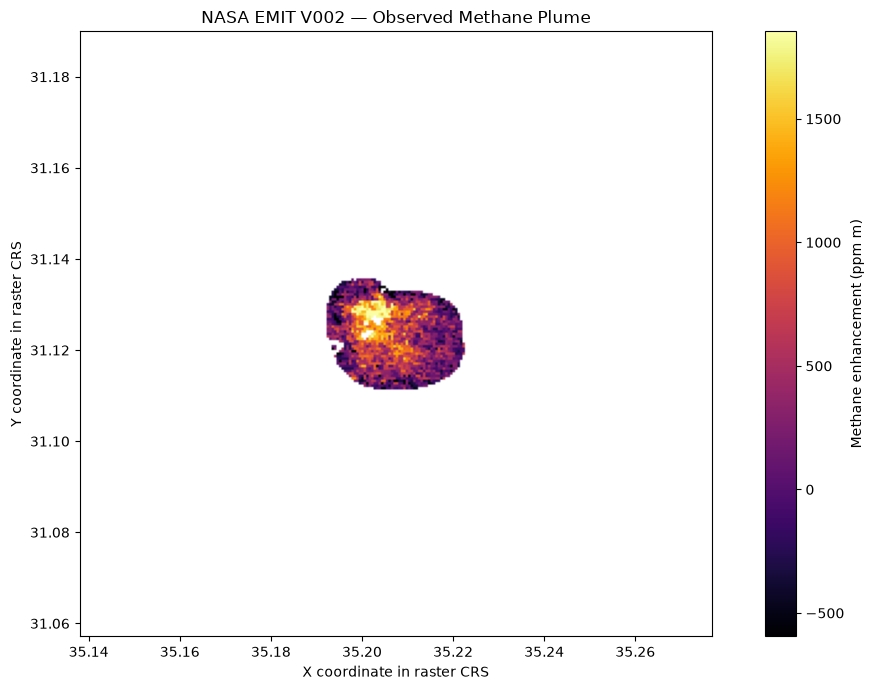

In [7]:
with rasterio.open(raster_path) as src:
    array = np.ma.masked_invalid(src.read(1, masked=True).astype("float64"))
    extent = plotting_extent(src)
    raster_crs = src.crs

valid = array.compressed()
if valid.size == 0:
    raise ValueError("Raster contains no valid band-1 pixels. Inspect the file and bands.")

print("Valid pixels:", valid.size)
print("Minimum enhancement:", round(float(valid.min()), 3), "ppm m")
print("Maximum enhancement:", round(float(valid.max()), 3), "ppm m")
print("Mean enhancement:", round(float(valid.mean()), 3), "ppm m")

# Percentile contrast enhances visual readability; not a numerical alteration to the source raster.
vmin, vmax = np.percentile(valid, [2, 98])
if vmin == vmax:
    vmin, vmax = float(valid.min()), float(valid.max()) + 1e-6

fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(
    array, cmap="inferno", origin="upper", extent=extent,
    vmin=vmin, vmax=vmax
)
fig.colorbar(im, ax=ax, label="Methane enhancement (ppm m)")
ax.set_title("NASA EMIT V002 — Observed Methane Plume")
ax.set_xlabel("X coordinate in raster CRS")
ax.set_ylabel("Y coordinate in raster CRS")
plt.tight_layout()
plt.show()


### Cell 8 — Inspect and overlay NASA plume polygons
The GeoJSON contains a geographical plume outline and potentially metadata such as emission-rate estimates. Metadata may contain `N/A` values. Do not derive kilograms/hour from enhancement values without a validated emissions methodology.

GeoJSON type: FeatureCollection
Feature count: 1
First feature properties:
  Plume ID: CH4_PlumeComplex-485
  Orbit: 2222205
  DCID: 1344041727
  UTC Time Observed: 2022-08-10T06:49:57Z
  Max Plume Concentration (ppm m): 3038.0
  Latitude of max concentration: 31.12789
  Longitude of max concentration: 35.20281
  Wind Speed (m/s): NA
  Wind Speed Std (m/s): NA
  Wind Speed Source: NA
  Emissions Rate Estimate (kg/hr): NA
  Emissions Rate Estimate Uncertainty (kg/hr): NA
  Fetch Length (m): NA
  DAAC Scene Names: ['EMIT_L2B_CH4ENH_V002_20220810T064957_2222205_033']
Vector CRS: EPSG:4326


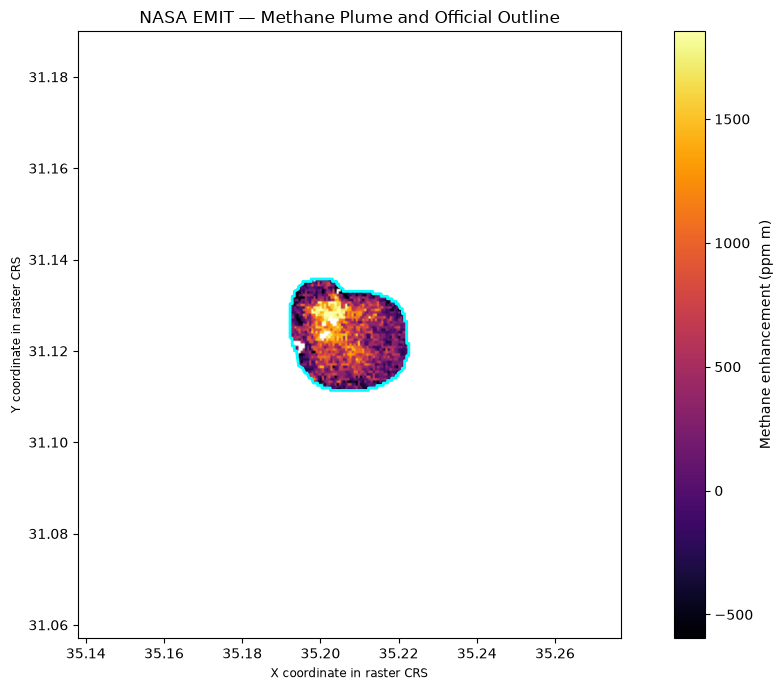

Saved figure: C:\Users\SOOQ ELASER\OneDrive\Desktop\RemoteSensing\MethaneScope\outputs\emit_real_plume_overlay.png


In [8]:
if vector_path is None:
    print("No GeoJSON downloaded. Plot above is still valid; review granule links.")
else:
    with open(vector_path, encoding="utf-8") as fh:
        geojson = json.load(fh)
    print("GeoJSON type:", geojson.get("type"))
    print("Feature count:", len(geojson.get("features", [])))
    if geojson.get("features"):
        properties = geojson["features"][0].get("properties", {})
        print("First feature properties:")
        for k, v in properties.items():
            print(f"  {k}: {str(v)[:150]}")

    plumes = gpd.read_file(vector_path)
    print("Vector CRS:", plumes.crs)
    if raster_crs is None:
        raise ValueError("Raster has no CRS; cannot safely overlay polygons.")
    if plumes.crs is None:
        raise ValueError("GeoJSON has no recognised CRS; inspect before assuming coordinates.")
    plumes = plumes.to_crs(raster_crs)

    fig, ax = plt.subplots(figsize=(11, 7))
    im = ax.imshow(array, cmap="inferno", origin="upper", extent=extent, vmin=vmin, vmax=vmax)
    plumes.boundary.plot(ax=ax, edgecolor="cyan", linewidth=2)
    fig.colorbar(im, ax=ax, label="Methane enhancement (ppm m)")
    ax.set_title("NASA EMIT — Methane Plume and Official Outline")
    ax.set_xlabel("X coordinate in raster CRS")
    ax.set_ylabel("Y coordinate in raster CRS")
    plt.tight_layout()
    final_plot = OUTPUTS / "emit_real_plume_overlay.png"
    fig.savefig(final_plot, dpi=160, bbox_inches="tight")
    plt.show()
    print("Saved figure:", final_plot)


### Cell 9 — Create a provenance record
We record the scientific product identifier, filenames, and processing environment. Later we will ingest this provenance into PostgreSQL/PostGIS.

In [9]:
record = {
    "provider": "NASA LP DAAC",
    "instrument": "NASA EMIT",
    "dataset_short_name": "EMITL2BCH4PLM",
    "version": "002",
    "doi": "10.5067/EMIT/EMITL2BCH4PLM.002",
    "raster_filename": raster_path.name,
    "geojson_filename": vector_path.name if vector_path else "",
    "enhancement_units": "ppm m",
    "data_origin": "real satellite data",
    "valid_pixels_band1": int(valid.size),
    "maximum_band1_value": float(valid.max()),
}
provenance = pd.DataFrame([record])
provenance_path = OUTPUTS / "emit_granule_provenance.csv"
provenance.to_csv(provenance_path, index=False)
print(provenance.T.to_string(header=False))
print("Saved:", provenance_path)


provider                                                    NASA LP DAAC
instrument                                                     NASA EMIT
dataset_short_name                                         EMITL2BCH4PLM
version                                                              002
doi                                       10.5067/EMIT/EMITL2BCH4PLM.002
raster_filename           EMIT_L2B_CH4PLM_002_20220810T064957_000485.tif
geojson_filename     EMIT_L2B_CH4PLMMETA_002_20220810T064957_000485.json
enhancement_units                                                  ppm m
data_origin                                          real satellite data
valid_pixels_band1                                                  1967
maximum_band1_value                                           3037.61377
Saved: C:\Users\SOOQ ELASER\OneDrive\Desktop\RemoteSensing\MethaneScope\outputs\emit_granule_provenance.csv


## Review questions
1. What is the difference between the synthetic raster we created last time and this EMIT raster?
2. What is the scientific meaning of **ppm m**? Why is it not the same as an emission rate in kg/hour?
3. What does the GeoJSON plume polygon tell us that the raster alone does not?
4. Why do we save a provenance record and inspect the nodata mask?

**Next lesson:** extract NASA plume attributes, validate metadata, inspect uncertainty, and build an ingestion table for multiple independent plumes.
